# 05 — Walk-Forward Modeling

**Goal:** Compare Ridge (price-only baseline) vs XGBoost (full features) using strictly temporal walk-forward validation. No random splits, no shuffling.

**Design:**
- Train window: 500 trading days (~2 years)
- Test window: 21 trading days (1 month)
- Step: 21 days
- Per-ticker models (each commodity trained independently)
- Feature sets: `FEATURES_PRICE` vs `FEATURES_FULL`
- Target: `future_return_5d`

**Evaluation:** IC (Spearman), hit rate, and out-of-sample R² per fold.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import json
import warnings
warnings.filterwarnings('ignore')

from src.config import DATA_PROCESSED_DIR
from src.models.walk_forward import walk_forward_validation
from src.models.baseline_models import make_ridge_pipeline
from src.models.tree_models import make_xgb_regressor, make_lgbm_regressor
from src.models.evaluation import (
    information_coefficient, hit_rate, sharpe_ratio
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

TRAIN_WINDOW = 500
TEST_WINDOW  = 21
STEP         = 21

## 1. Load panel and feature sets

In [2]:
panel = pd.read_parquet(DATA_PROCESSED_DIR / "modeling_panel.parquet")
panel["date"] = pd.to_datetime(panel["date"])

fs = json.load(open(DATA_PROCESSED_DIR / "feature_sets.json"))
FEATURES_PRICE = fs["FEATURES_PRICE"]
FEATURES_FULL  = fs["FEATURES_FULL"]
TARGET         = fs["TARGET"]

TICKERS = sorted(panel["ticker"].unique())
print(f"Panel: {panel.shape} | Tickers: {TICKERS}")
print(f"Price features  : {len(FEATURES_PRICE)}")
print(f"Full features   : {len(FEATURES_FULL)}")

Panel: (31430, 46) | Tickers: ['CORN', 'DBA', 'GLD', 'SOYB', 'UNG', 'USO', 'WEAT']
Price features  : 11
Full features   : 24


## 2. Run walk-forward validation — all tickers × 3 models

In [3]:
MODELS = {
    "Ridge (price)"  : (make_ridge_pipeline(),   FEATURES_PRICE),
    "Ridge (full)"   : (make_ridge_pipeline(),   FEATURES_FULL),
    "XGBoost (price)": (make_xgb_regressor(),    FEATURES_PRICE),
    "XGBoost (full)" : (make_xgb_regressor(),    FEATURES_FULL),
    "LightGBM (full)": (make_lgbm_regressor(),   FEATURES_FULL),
}

all_preds = {}   # {ticker: {model_name: results_df}}

for tkr in TICKERS:
    sub = (panel[panel["ticker"] == tkr]
           .sort_values("date")
           .reset_index(drop=True))
    all_preds[tkr] = {}

    for model_name, (model, features) in MODELS.items():
        feats_avail = [f for f in features if f in sub.columns]
        df_model = sub[["date", TARGET] + feats_avail].dropna()

        if len(df_model) < TRAIN_WINDOW + TEST_WINDOW:
            print(f"  {tkr} / {model_name}: insufficient rows ({len(df_model)}), skipping")
            continue

        res = walk_forward_validation(
            df_model, feats_avail, TARGET, model,
            train_window=TRAIN_WINDOW,
            test_window=TEST_WINDOW,
            step_size=STEP,
        )
        all_preds[tkr][model_name] = res

    print(f"{tkr}: {list(all_preds[tkr].keys())}")

print("\nDone.")

CORN: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']


DBA: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']


GLD: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']


SOYB: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']


UNG: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']


USO: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']


WEAT: ['Ridge (price)', 'Ridge (full)', 'XGBoost (price)', 'XGBoost (full)', 'LightGBM (full)']

Done.


## 3. Summary metrics table

In [4]:
rows = []
for tkr in TICKERS:
    for model_name, res in all_preds[tkr].items():
        valid = res.dropna(subset=["prediction", "actual"])
        ic  = information_coefficient(valid["prediction"], valid["actual"])
        hr  = hit_rate(valid["prediction"], valid["actual"])
        # naive signal return: long if pred>0, short if pred<0
        sign_ret = np.sign(valid["prediction"]) * valid["actual"]
        sh  = sharpe_ratio(sign_ret)
        rows.append({"ticker": tkr, "model": model_name,
                     "IC": round(ic, 4), "hit_rate": round(hr, 4),
                     "signal_sharpe": round(sh, 3), "n_folds": len(res) // TEST_WINDOW})

metrics = pd.DataFrame(rows)

# Pivot IC by model
ic_pivot = metrics.pivot(index="ticker", columns="model", values="IC")
print("=== Information Coefficient (Spearman ρ) ===")
print(ic_pivot.round(4).to_string())
print()

hr_pivot = metrics.pivot(index="ticker", columns="model", values="hit_rate")
print("=== Hit Rate ===")
print(hr_pivot.round(4).to_string())

=== Information Coefficient (Spearman ρ) ===
model   LightGBM (full)  Ridge (full)  Ridge (price)  XGBoost (full)  XGBoost (price)
ticker                                                                               
CORN             0.0575        0.0513        -0.0021          0.0460           0.0296
DBA              0.0467       -0.0046         0.0549          0.0610           0.0707
GLD              0.0800        0.0740         0.0451          0.1128           0.0799
SOYB             0.1151        0.0759         0.0542          0.1214           0.0934
UNG              0.0069        0.0219        -0.0699         -0.0045           0.0071
USO              0.0439        0.0058         0.0321          0.0205           0.0435
WEAT             0.0334        0.0145         0.0487          0.0292           0.0177

=== Hit Rate ===
model   LightGBM (full)  Ridge (full)  Ridge (price)  XGBoost (full)  XGBoost (price)
ticker                                                                       

## 4. IC heatmap — model × ticker

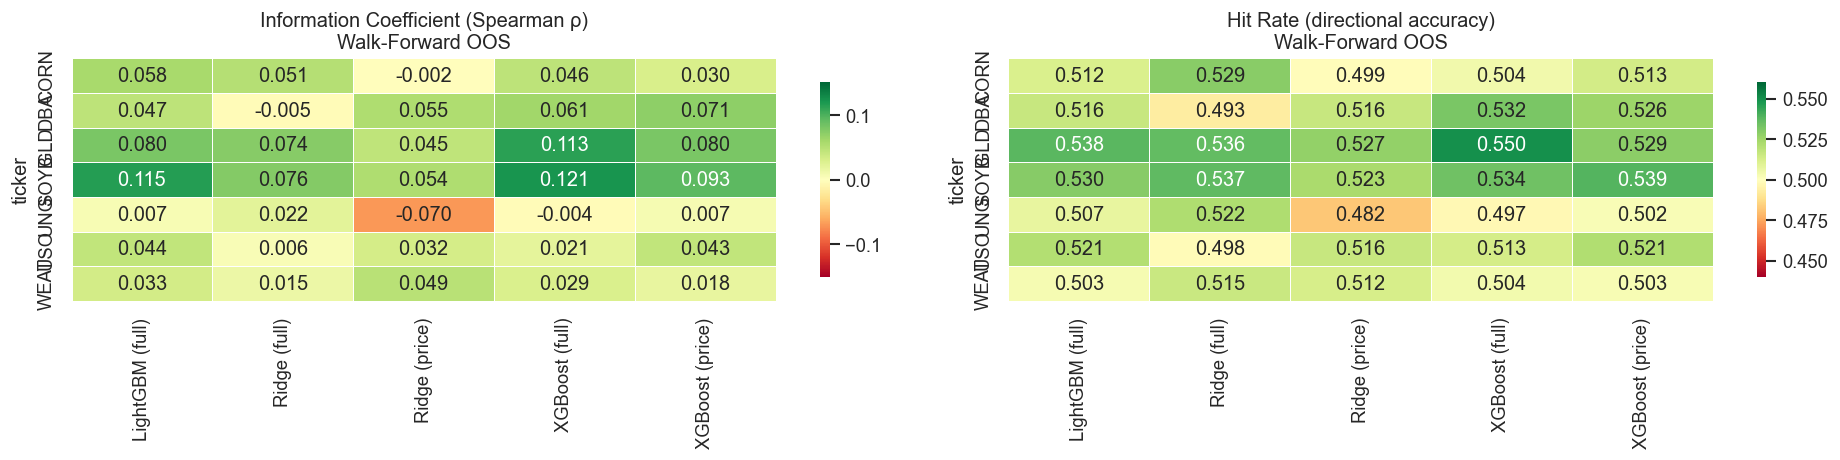

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

sns.heatmap(ic_pivot, annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, vmin=-0.15, vmax=0.15, ax=axes[0],
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes[0].set_title("Information Coefficient (Spearman ρ)\nWalk-Forward OOS")
axes[0].set_xlabel("")

sns.heatmap(hr_pivot, annot=True, fmt=".3f", cmap="RdYlGn",
            center=0.5, vmin=0.44, vmax=0.56, ax=axes[1],
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes[1].set_title("Hit Rate (directional accuracy)\nWalk-Forward OOS")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

## 5. Rolling IC over time — best model per ticker

Rolling monthly IC shows whether predictive power is stable or clustered in specific regimes.

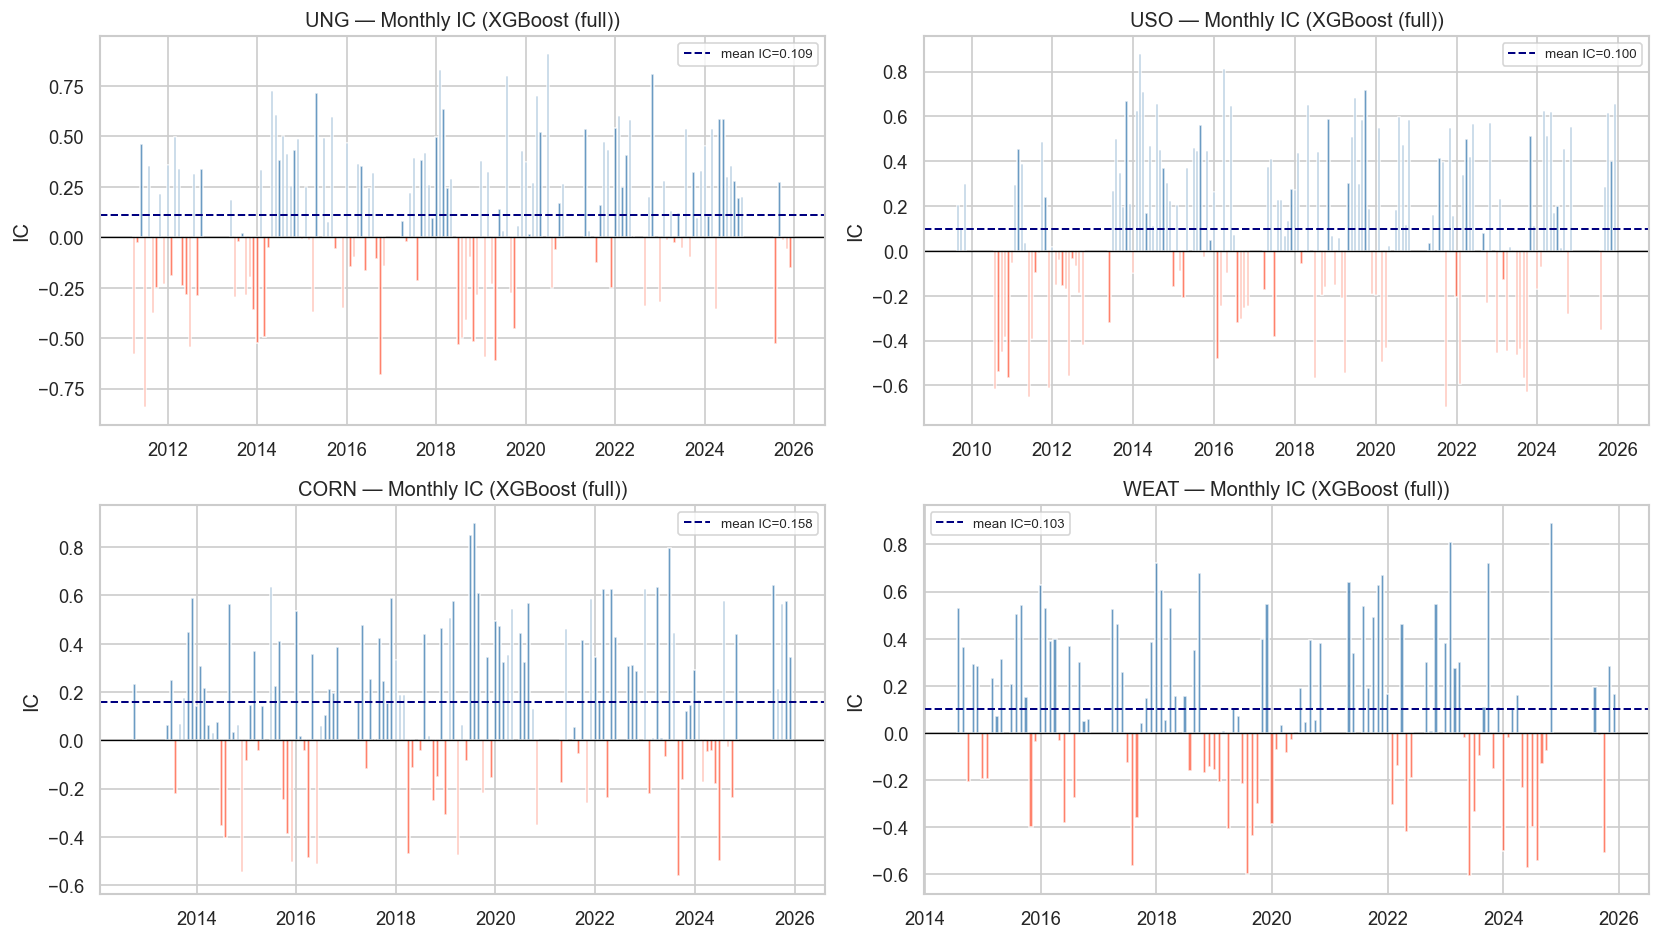

In [6]:
BEST_MODEL = "XGBoost (full)"
focus_tickers = ["UNG", "USO", "CORN", "WEAT"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=False)
axes = axes.flatten()

from scipy.stats import spearmanr

def monthly_ic_series(res_df):
    res = res_df.copy()
    res["date"] = pd.to_datetime(res["date"])
    res = res.dropna(subset=["prediction", "actual"])
    res["month"] = res["date"].dt.to_period("M")
    rows = []
    for period, g in res.groupby("month"):
        if len(g) < 5:
            continue
        rho, _ = spearmanr(g["prediction"], g["actual"])
        rows.append({"date": period.to_timestamp(), "ic": rho})
    return pd.DataFrame(rows).set_index("date")["ic"]

for ax, tkr in zip(axes, focus_tickers):
    if tkr not in all_preds or BEST_MODEL not in all_preds[tkr]:
        ax.set_visible(False)
        continue
    monthly_ic = monthly_ic_series(all_preds[tkr][BEST_MODEL])

    ax.bar(monthly_ic.index, monthly_ic.values,
           color=["tomato" if v < 0 else "steelblue" for v in monthly_ic.values],
           alpha=0.8, width=20)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(monthly_ic.mean(), color="navy", lw=1.2, ls="--",
               label=f"mean IC={monthly_ic.mean():.3f}")
    ax.set_title(f"{tkr} — Monthly IC ({BEST_MODEL})")
    ax.set_ylabel("IC")
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

## 6. XGBoost feature importance (average across tickers)

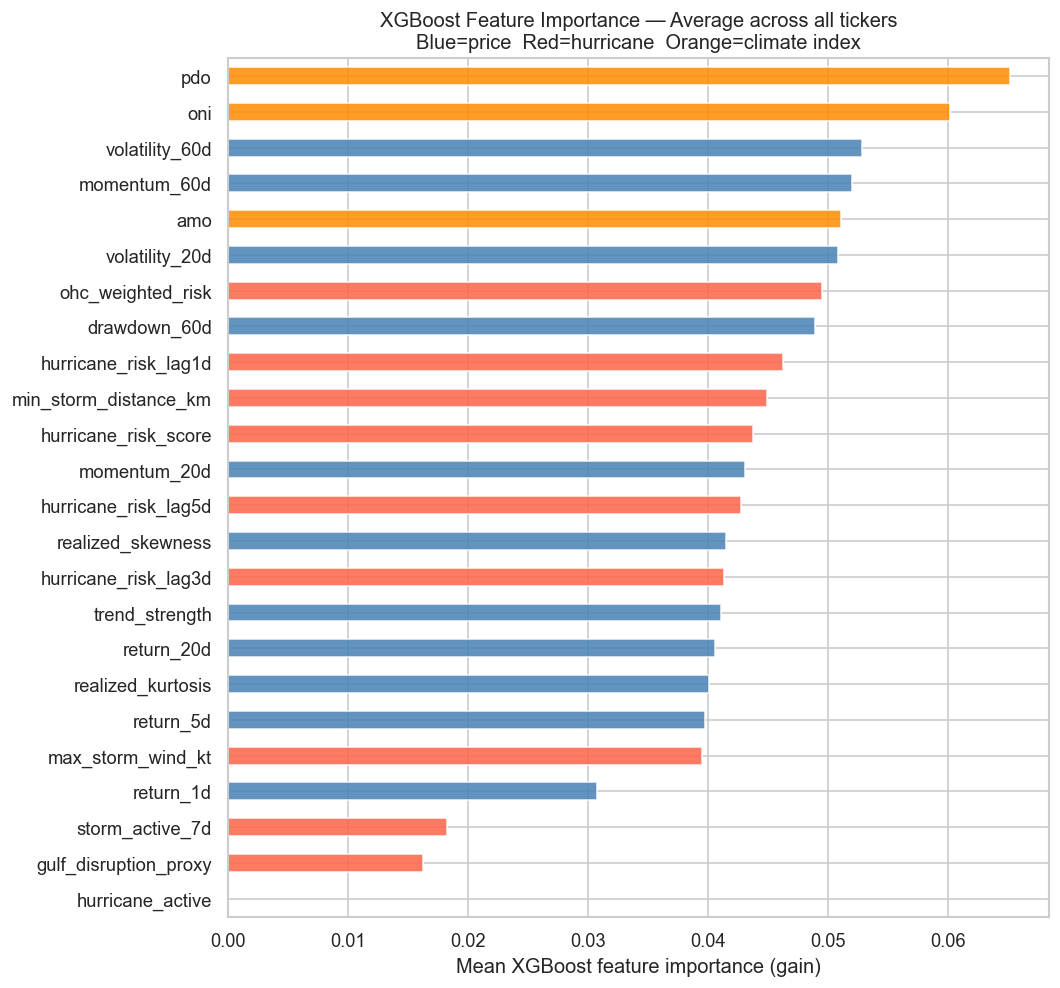

In [7]:
from xgboost import XGBRegressor
from sklearn.base import clone

# Fit one final XGBoost on 80% of each ticker's data to extract importances
importance_rows = []

for tkr in TICKERS:
    sub = (panel[panel["ticker"] == tkr]
           .sort_values("date").reset_index(drop=True))
    feats = [f for f in FEATURES_FULL if f in sub.columns]
    df_m  = sub[feats + [TARGET]].dropna()
    if len(df_m) < 200:
        continue

    cutoff = int(len(df_m) * 0.8)
    X_train = df_m[feats].iloc[:cutoff].fillna(0)
    y_train = df_m[TARGET].iloc[:cutoff]

    xgb = clone(make_xgb_regressor())
    xgb.fit(X_train, y_train)

    imp = dict(zip(feats, xgb.feature_importances_))
    imp["ticker"] = tkr
    importance_rows.append(imp)

imp_df = pd.DataFrame(importance_rows).set_index("ticker")
mean_imp = imp_df.mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, max(4, len(mean_imp) * 0.35)))
colors_imp = []
for f in mean_imp.index:
    if f in FEATURES_PRICE:        colors_imp.append("steelblue")
    elif f in ["amo","oni","pdo"]: colors_imp.append("darkorange")
    else:                          colors_imp.append("tomato")

mean_imp.plot.barh(ax=ax, color=colors_imp, alpha=0.85)
ax.set_xlabel("Mean XGBoost feature importance (gain)")
ax.set_title("XGBoost Feature Importance — Average across all tickers\n"
             "Blue=price  Red=hurricane  Orange=climate index")
plt.tight_layout()
plt.show()

## 7. Save walk-forward predictions

## 8. Bayesian Ridge Regression (PyMC) — uncertainty-aware predictions

Classical models give point predictions. A Bayesian model provides full posterior distributions over predictions, which is valuable for:
- **Risk sizing**: position sizes proportional to posterior precision
- **Regime awareness**: posterior variance widens in uncertain regimes
- **Interpretability**: coefficient credible intervals replace p-values

We fit a Bayesian linear model with weakly informative priors on a subset of tickers (GLD, SOYB) using price-only features to keep inference tractable.

In [8]:
import sys
sys.path.insert(0, '..')
from src.models.bayesian_models import BayesianLinearRegressor

BAYES_TICKERS  = ["GLD", "SOYB"]
BAYES_FEATURES = FEATURES_PRICE          # keep feature count small for MCMC
BAYES_DRAWS    = 500
BAYES_TUNE     = 500
BAYES_CHAINS   = 2

bayes_results = {}

for tkr in BAYES_TICKERS:
    sub = (panel[panel["ticker"] == tkr]
           .sort_values("date").reset_index(drop=True))
    feats = [f for f in BAYES_FEATURES if f in sub.columns]
    df_m  = sub[["date"] + feats + [TARGET]].dropna().reset_index(drop=True)

    # Use last 3 years as test, rest as train (strict temporal split)
    cutoff = int(len(df_m) * 0.75)
    train  = df_m.iloc[:cutoff]
    test   = df_m.iloc[cutoff:]

    X_train = train[feats].values
    y_train = train[TARGET].values
    X_test  = test[feats].values
    y_test  = test[TARGET].values

    blr = BayesianLinearRegressor(
        draws=BAYES_DRAWS, tune=BAYES_TUNE, chains=BAYES_CHAINS
    )
    blr.fit(X_train, y_train)

    pred_mean, pred_std = blr.predict(X_test)
    ic_bayes = information_coefficient(pred_mean, y_test)
    hr_bayes = hit_rate(pred_mean, y_test)

    bayes_results[tkr] = {
        "model":    blr,
        "test":     test,
        "pred_mean": pred_mean,
        "pred_std":  pred_std,
        "y_test":    y_test,
        "ic":        ic_bayes,
        "hit_rate":  hr_bayes,
        "feature_names": feats,
    }
    print(f"{tkr} Bayesian:  IC={ic_bayes:.4f}  HitRate={hr_bayes:.4f}  "
          f"avg_pred_std={pred_std.mean():.5f}")

print("\nBayesian inference complete.")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [alpha, betas, sigma]


Output()

Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 13 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


... (4 outputs left out)

Output()

Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 11 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


SOYB Bayesian:  IC=-0.0889  HitRate=0.4635  avg_pred_std=0.00123

Bayesian inference complete.


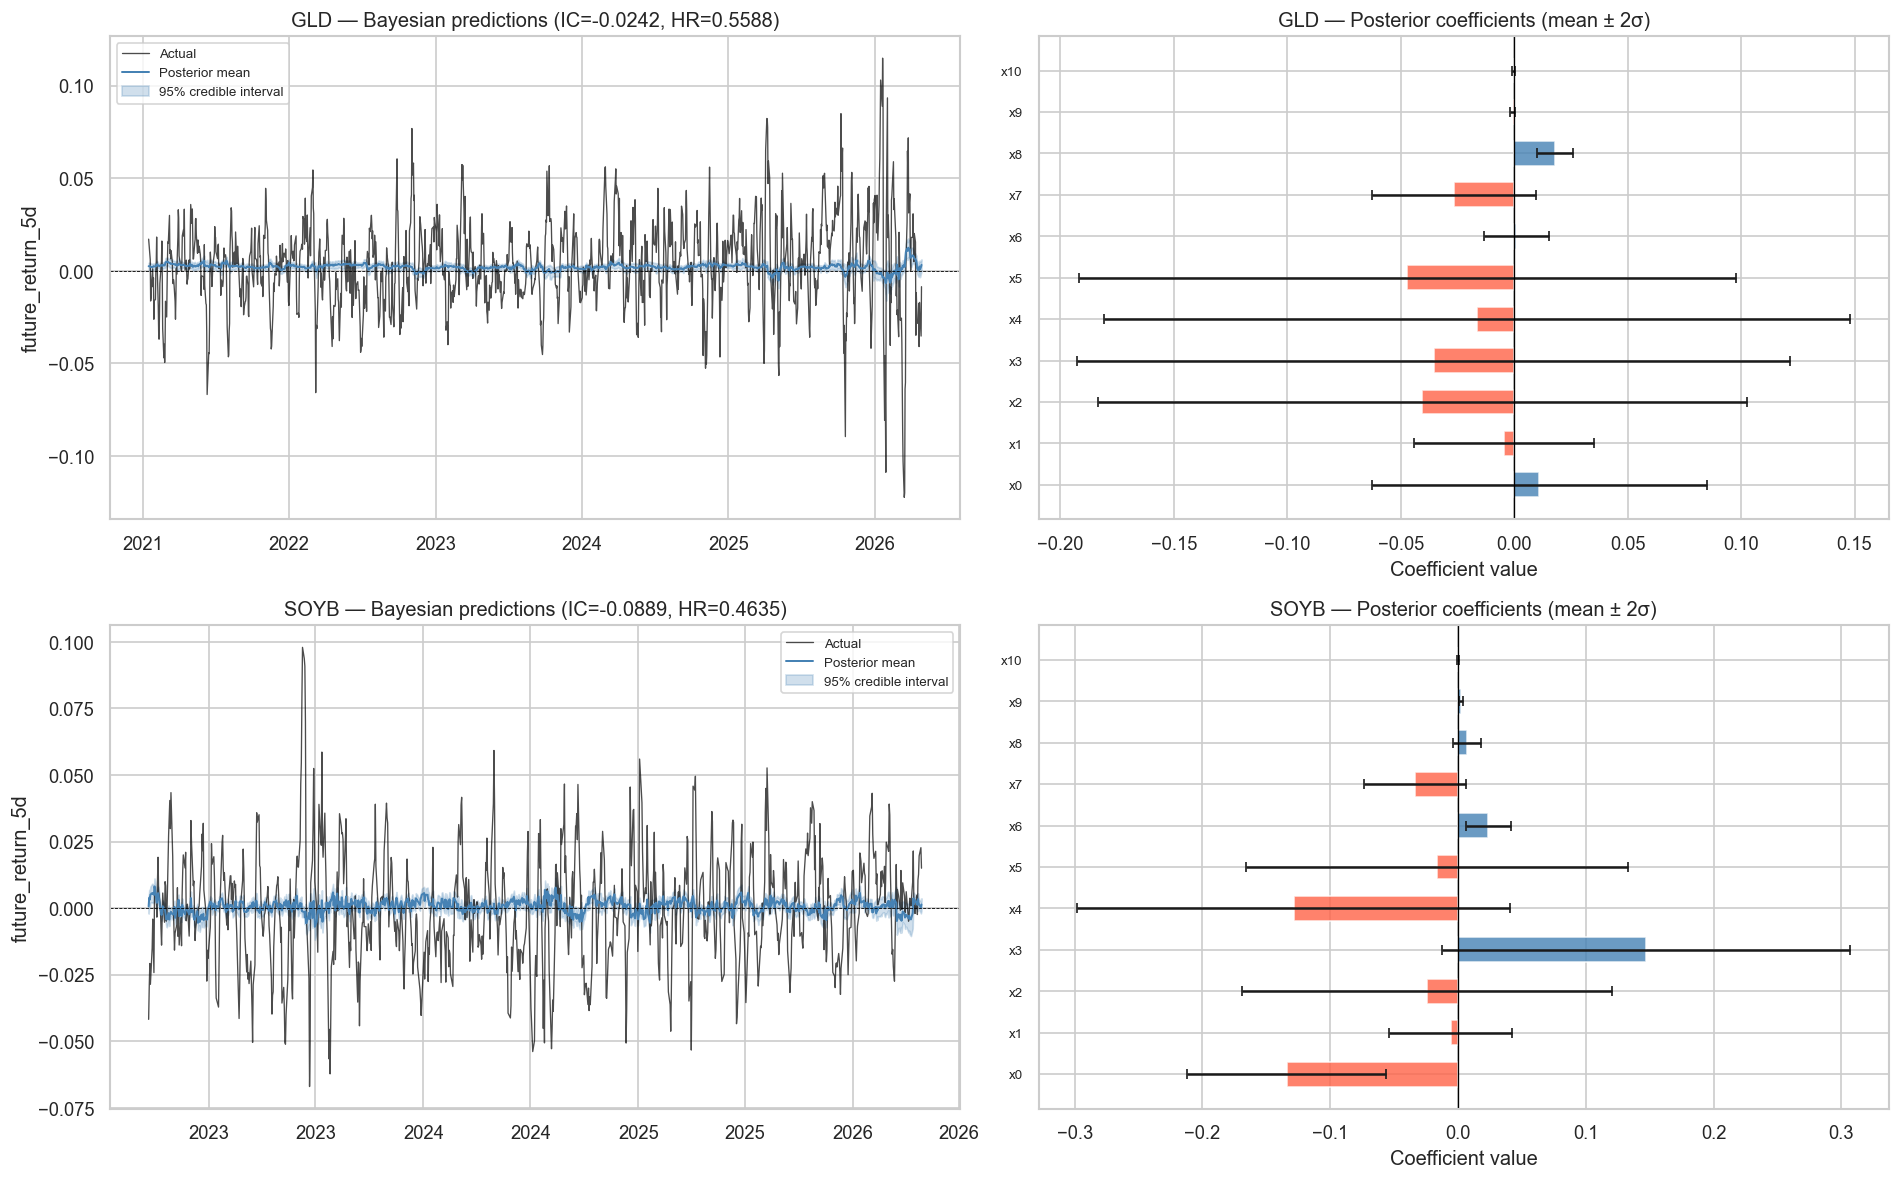

In [9]:
fig, axes = plt.subplots(len(BAYES_TICKERS), 2, figsize=(16, 5 * len(BAYES_TICKERS)))

for row_idx, tkr in enumerate(BAYES_TICKERS):
    r  = bayes_results[tkr]
    ax_pred, ax_coef = axes[row_idx]

    # --- left: prediction with uncertainty band ---
    dates     = r["test"]["date"].values
    pred_mean = r["pred_mean"]
    pred_std  = r["pred_std"]
    y_test    = r["y_test"]

    ax_pred.plot(dates, y_test,   color="black",     lw=0.8, label="Actual", alpha=0.7)
    ax_pred.plot(dates, pred_mean, color="steelblue", lw=1.2, label="Posterior mean")
    ax_pred.fill_between(dates,
                         pred_mean - 1.96 * pred_std,
                         pred_mean + 1.96 * pred_std,
                         alpha=0.25, color="steelblue", label="95% credible interval")
    ax_pred.axhline(0, color="black", lw=0.5, ls="--")
    ax_pred.set_title(f"{tkr} — Bayesian predictions (IC={r['ic']:.4f}, HR={r['hit_rate']:.4f})")
    ax_pred.set_ylabel(f"{TARGET}")
    ax_pred.legend(fontsize=8)
    ax_pred.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # --- right: coefficient posterior (mean ± 2σ) ---
    summary = r["model"].coefficient_summary()   # DataFrame: feature, mean, sd, hdi_3%, hdi_97%
    y_pos = range(len(summary))
    ax_coef.barh(y_pos, summary["mean"], xerr=2 * summary["sd"],
                 color=["tomato" if m < 0 else "steelblue" for m in summary["mean"]],
                 alpha=0.8, height=0.6, capsize=3)
    ax_coef.set_yticks(list(y_pos))
    ax_coef.set_yticklabels(summary["feature"], fontsize=8)
    ax_coef.axvline(0, color="black", lw=0.8)
    ax_coef.set_title(f"{tkr} — Posterior coefficients (mean ± 2σ)")
    ax_coef.set_xlabel("Coefficient value")

plt.tight_layout()
plt.savefig("../reports/figures/bayesian_predictions.png", dpi=150)
plt.show()

In [10]:
frames = []
for tkr in TICKERS:
    for model_name, res in all_preds[tkr].items():
        r = res.copy()
        r["ticker"]    = tkr
        r["model"]     = model_name
        frames.append(r)

wf_results = pd.concat(frames, ignore_index=True)
wf_results["date"] = pd.to_datetime(wf_results["date"])
wf_results.to_parquet(DATA_PROCESSED_DIR / "backtest_results.parquet", index=False)

print(f"Saved backtest_results.parquet — {wf_results.shape}")
print(wf_results[["ticker","model","date","prediction","actual"]].head(6).to_string())

# Also save metrics summary
metrics.to_csv(DATA_PROCESSED_DIR / "model_metrics.csv", index=False)
print(f"\nSaved model_metrics.csv — {metrics.shape}")

Saved backtest_results.parquet — (111006, 7)
  ticker          model       date  prediction    actual
0   CORN  Ridge (price) 2012-08-27   -0.028731  0.010238
1   CORN  Ridge (price) 2012-08-28   -0.027649  0.001774
2   CORN  Ridge (price) 2012-08-29   -0.027699 -0.008356
3   CORN  Ridge (price) 2012-08-30   -0.024650 -0.005849
4   CORN  Ridge (price) 2012-08-31   -0.024978 -0.011779
5   CORN  Ridge (price) 2012-09-04   -0.025565 -0.025336

Saved model_metrics.csv — (35, 6)
